In [24]:
import numpy as np
import pandas as pd
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.dates as mdates
from regression_utils import *
import os 

In [ ]:
#This is a summary of the SARIMA DATAMINING program:
#Adjusted R squared: 0.42052789776659205, p: 0, d: 1, q: 0, P:0, D: 0, Q:0
#Adjusted R squared: 0.4547474901194454, p: 0, d: 1, q: 1, P:0, D: 0, Q:0
#Adjusted R squared: 0.4505278415071833, p: 0, d: 1, q: 2, P:0, D: 0, Q:0
#Adjusted R squared: 0.44768806668148287, p: 1, d: 1, q: 0, P:0, D: 0, Q:0
#Adjusted R squared: 0.44347107937856467, p: 2, d: 1, q: 0, P:0, D: 0, Q:0
#Adjusted R squared: 0.4690046805570315, p: 2, d: 1, q: 2, P:0, D: 0, Q:0
#Adjusted R squared: 0.49150272513643223, p: 3, d: 1, q: 0, P:0, D: 0, Q:0
    

         Date  Water Volume      diff1
85 1998-02-01    30600608.0 -3175356.0
86 1998-03-01    33667807.0  3067199.0
87 1998-04-01    31762202.0 -1905605.0
88 1998-05-01    32499828.0   737626.0
89 1998-06-01    30791705.0 -1708123.0


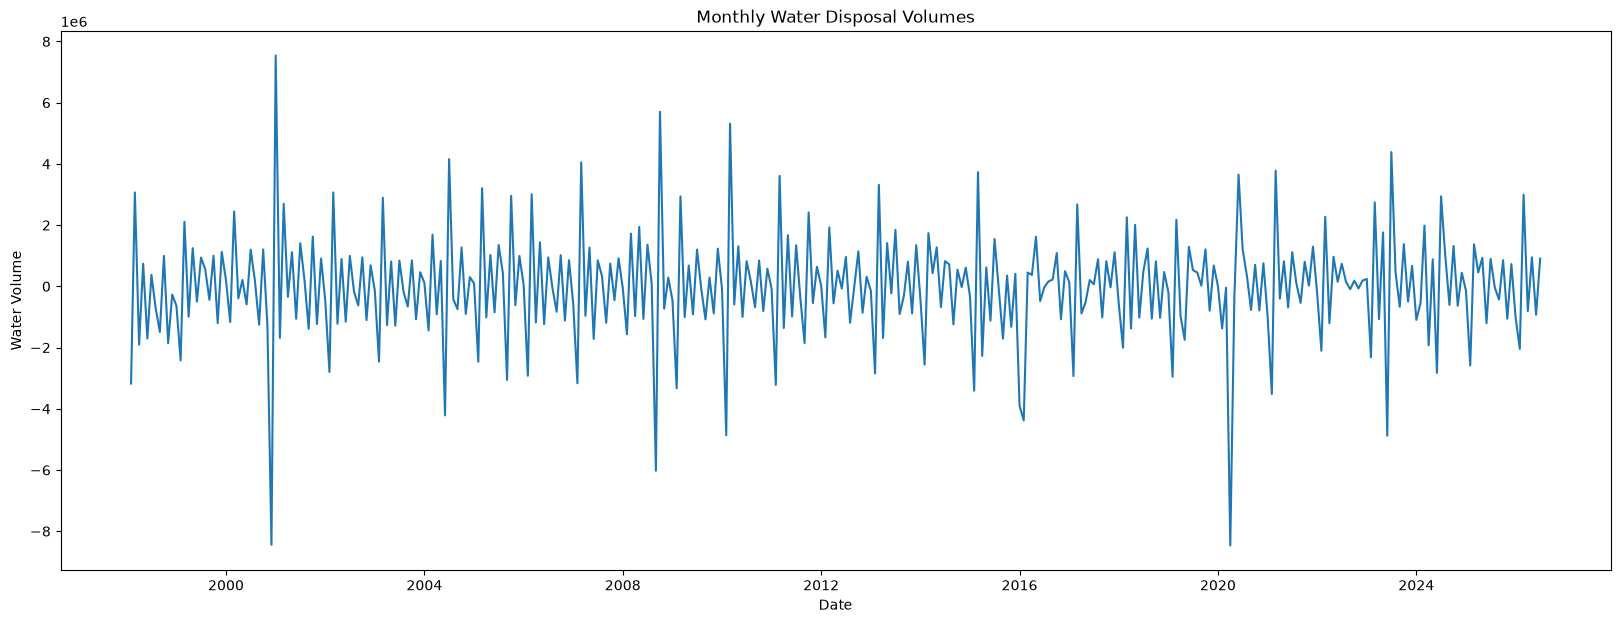

ADF Statistic: -5.581762921632424
p-value: 1.3914529392114988e-06
Stationary


In [22]:


original_df = pd.read_excel(r"C:\Users\LoganFrideley\East Texas Salt Water Disposal Company\Finance - Documents\Water Disposal History.xlsx")

monthly_water_vols = original_df[['Month/ Year', 'Total Disposed Water Volume']].copy()

# Filter out all Na values for water volumes.
monthly_water_vols = monthly_water_vols[~monthly_water_vols['Total Disposed Water Volume'].isna()]

# Changing column names to 'Water Volume'
monthly_water_vols['Water Volume'] = monthly_water_vols['Total Disposed Water Volume']

# Changing column name to Date and also making the type datetime64
monthly_water_vols['Date'] = monthly_water_vols['Month/ Year']
monthly_water_vols['Date'] = pd.to_datetime(monthly_water_vols['Date'])

# Dropping the old columns
monthly_water_vols = monthly_water_vols.drop(columns = ['Total Disposed Water Volume', 'Month/ Year'])
# Changing the order of the columns
monthly_water_vols = monthly_water_vols.loc[:, ['Date', 'Water Volume']]

#Differenced the data by 1 and the set is stationary.
monthly_water_vols['diff1'] = monthly_water_vols['Water Volume'].diff(1)
cleaned = monthly_water_vols.dropna()
print(cleaned.head())

# Data is clean from the SARIMA script, I must figure out how to plot this data.

fig, ax = plt.subplots(figsize=(20,7))

ax.plot(monthly_water_vols['Date'], monthly_water_vols['diff1'], label = 'Water Disposal Volume')
ax.set_title('Monthly Water Disposal Volumes')
ax.set_xlabel('Date')
ax.set_ylabel('Water Volume')
fig.savefig("Monthly Water Volumes")
plt.show()            

def check_stationarity(timeseries):
    result = adfuller(timeseries, autolag = 'AIC')
    p_value = result[1]
    print(f'ADF Statistic: {result[0]}')
    print(f'p-value: {p_value}')
    print('Stationary' if p_value < 0.05 else 'Non-stationary')

check_stationarity(cleaned['diff1'])




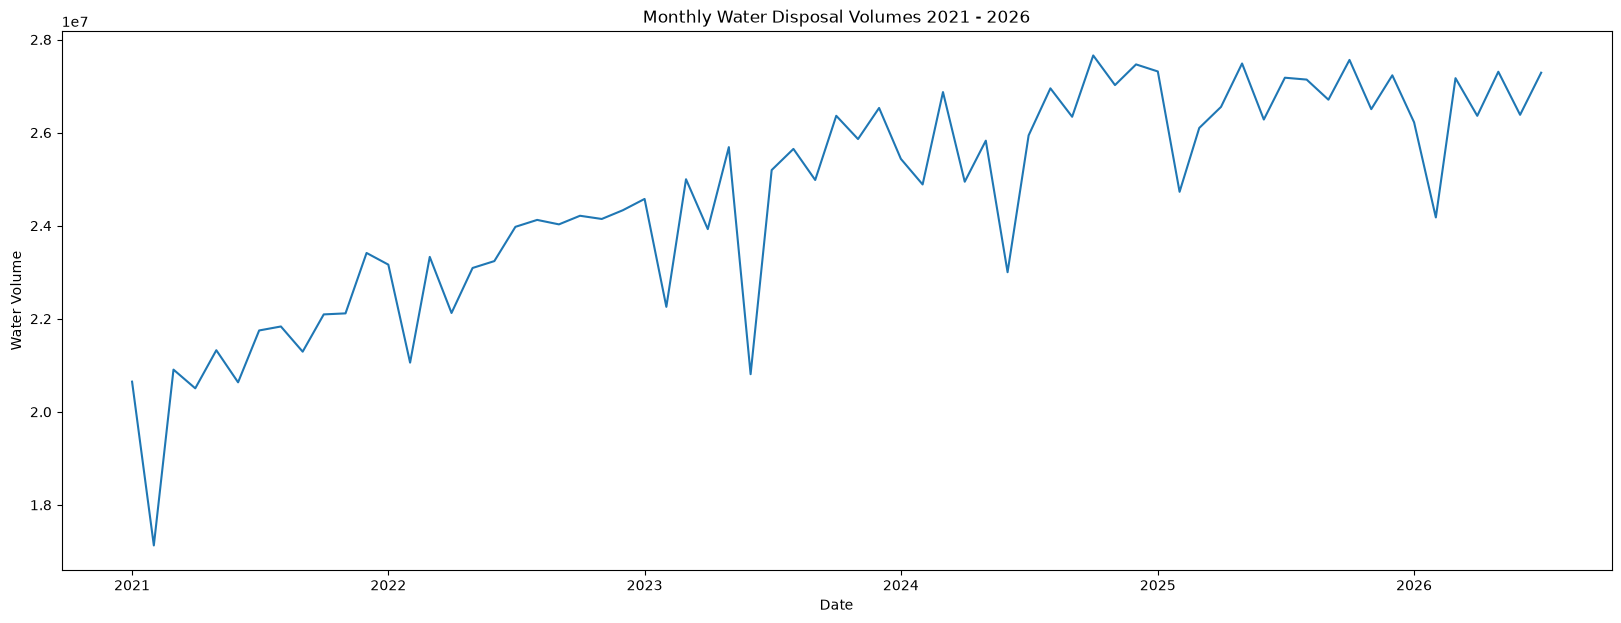

In [19]:


original_df = pd.read_excel(r"C:\Users\LoganFrideley\East Texas Salt Water Disposal Company\Finance - Documents\Water Disposal History.xlsx")

monthly_water_vols = original_df[['Month/ Year', 'Total Disposed Water Volume']].copy()

# Filter out all Na values for water volumes.
monthly_water_vols = monthly_water_vols[~monthly_water_vols['Total Disposed Water Volume'].isna()]

# Changing column names to 'Water Volume'
monthly_water_vols['Water Volume'] = monthly_water_vols['Total Disposed Water Volume']

# Changing column name to Date and also making the type datetime64
monthly_water_vols['Date'] = monthly_water_vols['Month/ Year']
monthly_water_vols['Date'] = pd.to_datetime(monthly_water_vols['Date'])

# Dropping the old columns
monthly_water_vols = monthly_water_vols.drop(columns = ['Total Disposed Water Volume', 'Month/ Year'])
# Changing the order of the columns
monthly_water_vols = monthly_water_vols.loc[:, ['Date', 'Water Volume']]
#Creating a Subset of the data after COVID
mask = (monthly_water_vols['Date'] >= '2021-01') & (monthly_water_vols['Date'] <= '2026-07')
subset = monthly_water_vols[mask]




# Data is clean from the SARIMA script, I must figure out how to plot this data.

fig, ax = plt.subplots(figsize=(20,7))

ax.plot(subset['Date'], subset['Water Volume'], label = 'Water Disposal Volume After COVID')
ax.set_title('Monthly Water Disposal Volumes 2021 - 2026')
ax.set_xlabel('Date')
ax.set_ylabel('Water Volume')
fig.savefig("Monthly Water Volumes 2021 - 2026")
plt.show()

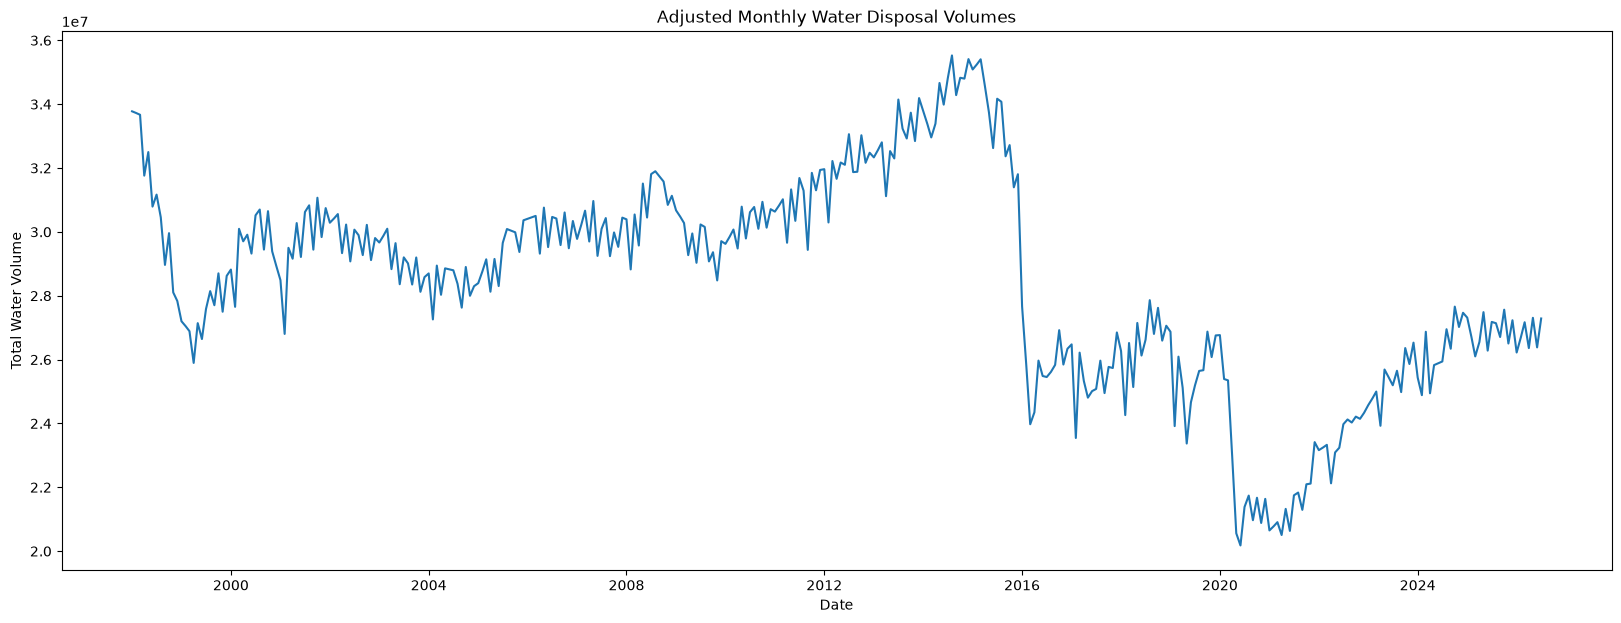

In [10]:
#Accessing the adjusted values from SARIMA Project
adjusted_df = pd.read_excel(r"C:\Users\LoganFrideley\OneDrive - East Texas Salt Water Disposal Company\Documents\SARIMA Project\Water Disposal History.xlsx", sheet_name='Sheet2')
adjusted = adjusted_df[['Date', 'Total Water Volume 1']]



fig, ax = plt.subplots(figsize=(20,7))

ax.plot(adjusted['Date'], adjusted['Total Water Volume 1'], label = 'Adjusted Water Disposal Volume')
ax.set_title('Adjusted Monthly Water Disposal Volumes')
ax.set_xlabel('Date')
ax.set_ylabel('Total Water Volume')
fig.savefig("Adjusted Monthly Water Volumes")
plt.show()

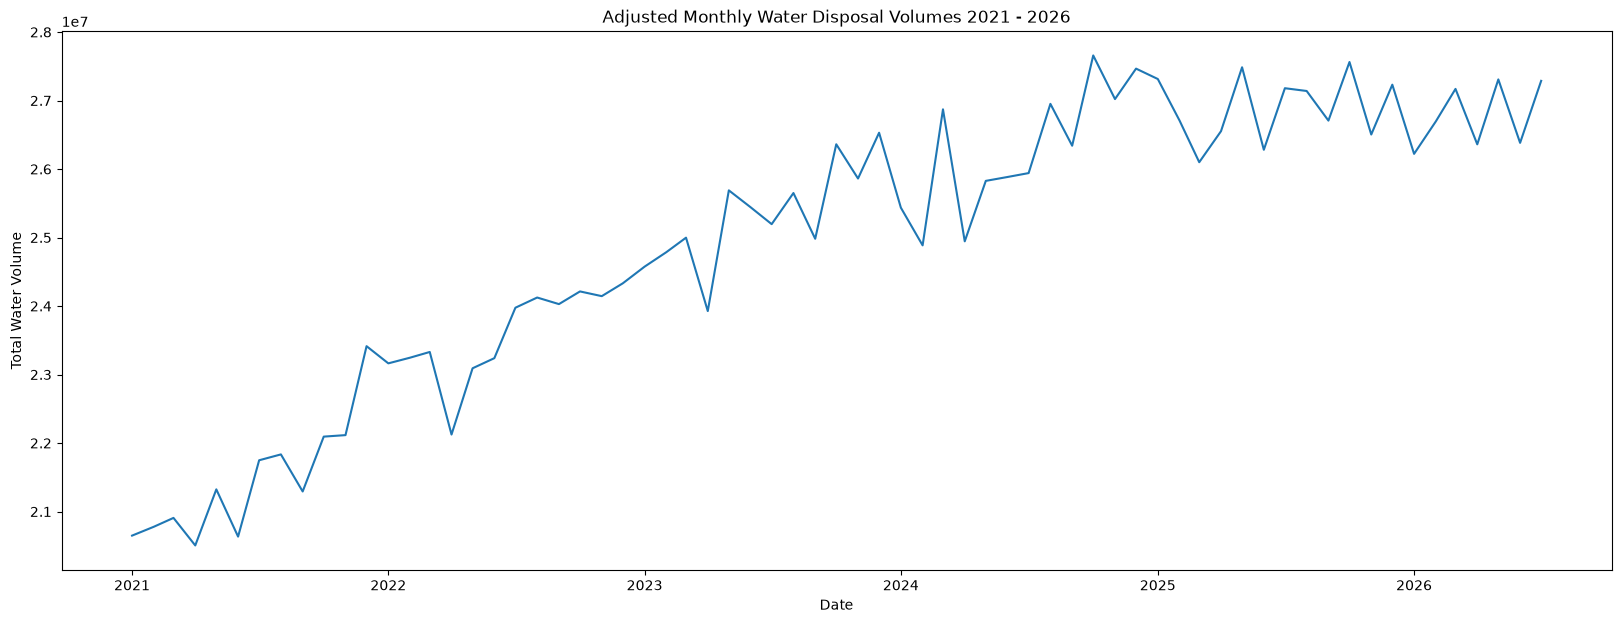

In [9]:
#Accessing the adjusted values from SARIMA Project
adjusted_df = pd.read_excel(r"C:\Users\LoganFrideley\OneDrive - East Texas Salt Water Disposal Company\Documents\SARIMA Project\Water Disposal History.xlsx", sheet_name='Sheet2')
adjusted = adjusted_df[['Date', 'Total Water Volume 1']]

mask = (adjusted['Date'] >= '2021-01') & (adjusted['Date'] <= '2026-07')
adjusted_subset = adjusted[mask]
fig, ax = plt.subplots(figsize=(20,7))

ax.plot(adjusted_subset['Date'], adjusted_subset['Total Water Volume 1'], label = 'Adjusted Water Disposal Volume')
ax.set_title('Adjusted Monthly Water Disposal Volumes 2021 - 2026')
ax.set_xlabel('Date')
ax.set_ylabel('Total Water Volume')
fig.savefig("Adjusted Monthly Water Volumes 2021 - 2026")
plt.show()

In [ ]:





df = pd.read_excel(r"C:\Users\LoganFrideley\East Texas Salt Water Disposal Company\Finance - Documents\Water Disposal History.xlsx")
#pd.set_option('display.max_rows', 90)

monthly_water_vols = df[['Month/ Year', 'Total Disposed Water Volume']].copy()
# Filter out all Na values for water volumes.
monthly_water_vols = monthly_water_vols[~monthly_water_vols['Total Disposed Water Volume'].isna()]
# Changing column names to 'Water Volume'
monthly_water_vols['Water Volume'] = monthly_water_vols['Total Disposed Water Volume']
# Changing column name to Date and also making the type datetime64
monthly_water_vols['Date'] = monthly_water_vols['Month/ Year']
monthly_water_vols['Date'] = pd.to_datetime(monthly_water_vols['Date'])

# Dropping the old columns
monthly_water_vols = monthly_water_vols.drop(columns = ['Total Disposed Water Volume', 'Month/ Year'])
# Changing the order of the columns
monthly_water_vols = monthly_water_vols.loc[:, ['Date', 'Water Volume']]


# This function checks if the data has 'stationarity'
#Also checks and prints the p_value
# Uses the augmented Dickey-Fuller test
def check_stationarity(timeseries):
    result = adfuller(timeseries, autolag = 'AIC')
    p_value = result[1]
    print(f'ADF Statistic: {result[0]}')
    print(f'p-value: {p_value}')
    print('Stationary' if p_value < 0.05 else 'Non-stationary')


#check_stationarity(monthly_water_vols['Water Volume'])
monthly_water_vols['diff1'] = monthly_water_vols['Water Volume'].diff(1)
cleaned = monthly_water_vols.dropna()

#Changing the dataframe to represent the last 5 years.
mask = (cleaned['Date'] >= '2021-01-01') & (cleaned['Date'] <= '2026-07-01')
subset = cleaned[mask]

#Assigning Training data set
training_mask = (subset['Date'] >= '2021-01-01') & (subset['Date'] <= '2025-12-01')
training = subset[training_mask]

#Assigning Validation data
validation_mask = (subset['Date'] >= '2026-01-01') & (subset['Date'] <= '2026-07-01')
validation = subset[validation_mask]

#training_data = np.asarray(training['Water Volume'])
os.chdir(r"C:\Users\LoganFrideley\OneDrive - East Texas Salt Water Disposal Company\Documents\SARIMA Project")
#We are datamining for the optimal parameters for the SARIMA model.
with open("SARIMA OUTPUT Real.txt", "w") as fhand:
        
    #SARIMA MODEL Parameters
    for p in range(0, 4):
        for d in range(0, 4):
            for q in range(0, 4):
                for P in range(0, 4):
                    for D in range(0, 4):
                        for Q in range(0, 4):
                            # p, d, q = 1, 2, 1
                            # P, D, Q, s = 1, 1, 1, 12
                            
                            model = SARIMAX(training['diff1'], order=(p, d, q), seasonal_order=(p, d, q, 12))
                            results = model.fit()
                            forecast_periods = 7
                            forecast = results.forecast(forecast_periods)
                            adjusted = adj_R_squared(validation['diff1'], forecast, cleaned)
                           
                            fhand.write(f"Adjusted R squared: {adjusted}, p: {p}, d: {d}, q: {q}, P:{P}, D: {D}, Q:{Q}\n")
                          
                        
                            
                            
    # fig, ax = plt.subplots()

    # ax.plot(training['Date'], training['Water Volume'], label='Observed')
    # ax.plot(validation['Date'], forecast, label='Forecast', color='red')
    # ax.set_title("Disposal Volume Forecast")
    # ax.set_xlabel("Date")
    # ax.set_ylabel("Volume")
    # ax.grid()
    # fig.legend()
    # fig.show()
    
    # fig, ax = plt.subplots()
    # ax.plot(training['Date'], training['Water Volume'], label='Observed')
    # ax.plot(validation['Date'], validation['Water Volume'], label='Actual', color='cyan')
    # ax.set_title("Disposal Volume Actual")
    # ax.set_xlabel("Date")
    # ax.set_ylabel("Volume")
    # ax.grid()
    # fig.legend()
    # fig.show() 
                    


C:\Users\LoganFrideley\anaconda3\envs\Analytics\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'
